In [1]:
# Import libraries and packages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GroupShuffleSplit

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.metrics import log_loss, brier_score_loss
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import f1_score
from sklearn.model_selection import cross_val_score

In [2]:
# Mount Google drive for access to files

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **DEFINING FUNCTIONS**

In [3]:
# Function to create results dataframe for % top pick accuracy

def create_prediction_results(test_ids, train_ids, test_target, train_target,
                             test_preds, train_preds):

    # Create results dataframes
    test_results_df = pd.DataFrame({
        'Film_ID': test_ids,
        'Actual_Winner': test_target,
        'Win_Probability': test_preds
    })

    train_results_df = pd.DataFrame({
        'Film_ID': train_ids,
        'Actual_Winner': train_target,
        'Win_Probability': train_preds
    })

    # Extract Oscar Year from Film_ID
    test_results_df['Oscar_Year'] = test_results_df['Film_ID'].str.extract('(\d{4})')
    train_results_df['Oscar_Year'] = train_results_df['Film_ID'].str.extract('(\d{4})')

    return test_results_df, train_results_df

<>:20: SyntaxWarning: invalid escape sequence '\d'
<>:21: SyntaxWarning: invalid escape sequence '\d'
<>:20: SyntaxWarning: invalid escape sequence '\d'
<>:21: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipython-input-388223204.py:20: SyntaxWarning: invalid escape sequence '\d'
  test_results_df['Oscar_Year'] = test_results_df['Film_ID'].str.extract('(\d{4})')
/tmp/ipython-input-388223204.py:21: SyntaxWarning: invalid escape sequence '\d'
  train_results_df['Oscar_Year'] = train_results_df['Film_ID'].str.extract('(\d{4})')


In [4]:
# Results dataframes for acting dataset – with added Category

def create_acting_results(test_ids, train_ids, test_target, train_target,
                         test_category, train_category, test_preds, train_preds):

    # Create results dataframes
    test_results_df = pd.DataFrame({
        'Film_ID': test_ids,
        'Actual_Winner': test_target,
        'Win_Probability': test_preds,
        'Category': test_category
    })

    train_results_df = pd.DataFrame({
        'Film_ID': train_ids,
        'Actual_Winner': train_target,
        'Win_Probability': train_preds,
        'Category': train_category
    })

    # Extract Oscar Year from Film_ID
    test_results_df['Oscar_Year'] = test_results_df['Film_ID'].str.extract('(\d{4})')
    train_results_df['Oscar_Year'] = train_results_df['Film_ID'].str.extract('(\d{4})')

    return test_results_df, train_results_df

<>:22: SyntaxWarning: invalid escape sequence '\d'
<>:23: SyntaxWarning: invalid escape sequence '\d'
<>:22: SyntaxWarning: invalid escape sequence '\d'
<>:23: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipython-input-4294066736.py:22: SyntaxWarning: invalid escape sequence '\d'
  test_results_df['Oscar_Year'] = test_results_df['Film_ID'].str.extract('(\d{4})')
/tmp/ipython-input-4294066736.py:23: SyntaxWarning: invalid escape sequence '\d'
  train_results_df['Oscar_Year'] = train_results_df['Film_ID'].str.extract('(\d{4})')


In [5]:
# Function for calculating overall accuracy for 1st, 2nd and 3rd probability pick
# Reference: Claude.ai
def calculate_top_n_accuracy(results_df, n=1):
    correct_predictions = 0
    total_years = 0

    for year in results_df['Oscar_Year'].unique():
        year_data = results_df[results_df['Oscar_Year'] == year]
        # Sort this year's data by probability (highest first)
        year_data_sorted = year_data.sort_values('Win_Probability', ascending=False)
        top_n_picks = year_data_sorted.head(n)  # Top N predictions for this year

        if top_n_picks['Actual_Winner'].sum() > 0:  # Any winners in top N?
            correct_predictions += 1
        total_years += 1

    return correct_predictions / total_years


# Function for calculating F1 score
# Reference: Claude.ai
def calculate_f1_score(results_df):
    y_true = []
    y_pred = []

    for year in results_df['Oscar_Year'].unique():
        year_data = results_df[results_df['Oscar_Year'] == year]
        year_data_sorted = year_data.sort_values('Win_Probability', ascending=False)

        # Get actual winners for this year
        actual_winners = year_data['Actual_Winner'].values

        # Get predicted winner (highest probability)
        predicted_winners = np.zeros(len(year_data))
        predicted_winners[0] = 1  # Mark the highest probability film as predicted winner

        # Reorder predicted winners to match original order
        original_order_indices = year_data_sorted.index
        reordered_predictions = np.zeros(len(year_data))
        for i, orig_idx in enumerate(original_order_indices):
            reordered_predictions[list(year_data.index).index(orig_idx)] = predicted_winners[i]

        y_true.extend(actual_winners)
        y_pred.extend(reordered_predictions)

    return f1_score(y_true, y_pred)

In [6]:
# Need custom Acting F1 function as dataset combines 4x categories - this works it out for each
# Reference: Claude.ai
def calculate_f1_by_category(results_df):
    f1_scores = {}

    for category in results_df['Category'].unique():
        category_data = results_df[results_df['Category'] == category]

        y_true = []
        y_pred = []

        for year in category_data['Oscar_Year'].unique():
            year_data = category_data[category_data['Oscar_Year'] == year]
            year_data_sorted = year_data.sort_values('Win_Probability', ascending=False)

            # Get actual winners for this year/category
            actual_winners = year_data['Actual_Winner'].values

            # Get predicted winner (highest probability)
            predicted_winners = np.zeros(len(year_data))
            predicted_winners[0] = 1  # Mark highest probability as predicted winner

            # Reorder to match original order
            original_order_indices = year_data_sorted.index
            reordered_predictions = np.zeros(len(year_data))
            for i, orig_idx in enumerate(original_order_indices):
                reordered_predictions[list(year_data.index).index(orig_idx)] = predicted_winners[i]

            y_true.extend(actual_winners)
            y_pred.extend(reordered_predictions)

        f1_scores[category] = f1_score(y_true, y_pred)

    return f1_scores

In [7]:
# Function for performing cross-validation
# Using 5x splits on GroupShuffleSplit
# Reference: Claude.ai

def cross_validate_oscar_model(model, X, y, groups, cv_splits=5):
    cv = GroupShuffleSplit(n_splits=cv_splits, test_size=0.2, random_state=42)

    roc_scores = []
    f1_scores = []

    for train_idx, test_idx in cv.split(X, y, groups=groups):
        # Train model
        model.fit(X.iloc[train_idx], y.iloc[train_idx])

        # Get predictions
        probs = model.predict_proba(X.iloc[test_idx])[:, 1]

        # Calculate metrics
        roc_scores.append(roc_auc_score(y.iloc[test_idx], probs))

        # Create results df for cross-val F1 calculation
        fold_results_df = pd.DataFrame({
            'Film_ID': pic_ids.iloc[test_idx],
            'Actual_Winner': pic_target.iloc[test_idx],
            'Win_Probability': probs,
            'Oscar_Year': pic_groups.iloc[test_idx]
        })

        # Custom F1 calculation using previous function
        f1_scores.append(calculate_f1_score(fold_results_df))

    return np.mean(roc_scores), np.std(roc_scores), np.mean(f1_scores), np.std(f1_scores)


# Cross-validation function for Director

def cross_validate_oscar_model_dir(model, X, y, groups, cv_splits=5):
    cv = GroupShuffleSplit(n_splits=cv_splits, test_size=0.2, random_state=42)

    roc_scores = []
    f1_scores = []

    for train_idx, test_idx in cv.split(X, y, groups=groups):
        # Train model
        model.fit(X.iloc[train_idx], y.iloc[train_idx])

        # Get predictions
        probs = model.predict_proba(X.iloc[test_idx])[:, 1]

        # Calculate metrics
        roc_scores.append(roc_auc_score(y.iloc[test_idx], probs))

        # Create results df for cross-val F1 calculation
        fold_results_df = pd.DataFrame({
            'Film_ID': dir_ids.iloc[test_idx],
            'Actual_Winner': dir_target.iloc[test_idx],
            'Win_Probability': probs,
            'Oscar_Year': dir_groups.iloc[test_idx]
        })

        # Custom F1 calculation using previous function
        f1_scores.append(calculate_f1_score(fold_results_df))

    return np.mean(roc_scores), np.std(roc_scores), np.mean(f1_scores), np.std(f1_scores)


# Function for cross-validating MALE ACTING dataset
# Using 5x splits on GroupShuffleSplit for cross-validation
# adapted for category-specific F1 score calculation
# Reference: Claude.ai

def cross_validate_oscar_model_acting(model, X, y, groups, cv_splits=5):
    cv = GroupShuffleSplit(n_splits=cv_splits, test_size=0.2, random_state=42)

    roc_scores = []
    category_f1_scores = []  # Store dictionaries instead of single values

    for train_idx, test_idx in cv.split(X, y, groups=groups):
        # Train model
        model.fit(X.iloc[train_idx], y.iloc[train_idx])

        # Get predictions
        probs = model.predict_proba(X.iloc[test_idx])[:, 1]

        # Calculate metrics
        roc_scores.append(roc_auc_score(y.iloc[test_idx], probs))

        # Create results df for cross-val F1 calculation
        fold_results_df = pd.DataFrame({
            'Film_ID': act_male_ids.iloc[test_idx],
            'Actual_Winner': act_male_target.iloc[test_idx],
            'Win_Probability': probs,
            'Category': act_male_category.iloc[test_idx],
            'Oscar_Year': act_male_groups.iloc[test_idx]
        })

        # Store the dictionary of F1 scores by category
        category_f1_scores.append(calculate_f1_by_category(fold_results_df))

    # Calculate average F1 scores per category across all folds
    categories = category_f1_scores[0].keys()  # Get category names
    avg_f1_by_category = {}
    std_f1_by_category = {}

    for category in categories:
        category_scores = [fold[category] for fold in category_f1_scores]
        avg_f1_by_category[category] = np.mean(category_scores)
        std_f1_by_category[category] = np.std(category_scores)

    return (np.mean(roc_scores), np.std(roc_scores),
            avg_f1_by_category, std_f1_by_category)


# Function for cross-validating FEMALE ACTING data
# Using 5x splits on GroupShuffleSplit for cross-validation
# adapted for category-specific F1 score calculation
# Reference: Claude.ai

def cross_validate_oscar_model_female_acting(model, X, y, groups, cv_splits=5):
    cv = GroupShuffleSplit(n_splits=cv_splits, test_size=0.2, random_state=42)

    roc_scores = []
    category_f1_scores = []  # Store dictionaries instead of single values

    for train_idx, test_idx in cv.split(X, y, groups=groups):
        # Train model
        model.fit(X.iloc[train_idx], y.iloc[train_idx])

        # Get predictions
        probs = model.predict_proba(X.iloc[test_idx])[:, 1]

        # Calculate metrics
        roc_scores.append(roc_auc_score(y.iloc[test_idx], probs))

        # Create results df for cross-val F1 calculation
        fold_results_df = pd.DataFrame({
            'Film_ID': act_female_ids.iloc[test_idx],
            'Actual_Winner': act_female_target.iloc[test_idx],
            'Win_Probability': probs,
            'Category': act_female_category.iloc[test_idx],
            'Oscar_Year': act_female_groups.iloc[test_idx]
        })

        # Store the dictionary of F1 scores by category
        category_f1_scores.append(calculate_f1_by_category(fold_results_df))

    # Calculate average F1 scores per category across all folds
    categories = category_f1_scores[0].keys()  # Get category names
    avg_f1_by_category = {}
    std_f1_by_category = {}

    for category in categories:
        category_scores = [fold[category] for fold in category_f1_scores]
        avg_f1_by_category[category] = np.mean(category_scores)
        std_f1_by_category[category] = np.std(category_scores)

    return (np.mean(roc_scores), np.std(roc_scores),
            avg_f1_by_category, std_f1_by_category)

# **BEST PICTURE MODEL**

### SPLITTING AND SCALING

In [8]:
# Import the data file

pic_data = '15iYoQWE6oGFbK5qlefNKkrSBDd1f8mtE'
pic_url = f'https://drive.google.com/uc?id={pic_data}'

pic_df = pd.read_csv(pic_url)
pic_df

,Film,Oscar_Year,Winner,Total_Oscar_noms,Oscar_nom_director,Rating_IMDB,Rating_rtaudience,Rating_rtcritic,Release_Q1,Release_Q2,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,Best_Editing_Nom
0,The Apartment,1961,1,10,1,8.3,94,93,0,0,...,0,0,0,0,0,0,0,125,1,1
1,The Alamo,1961,0,6,0,6.9,64,50,0,0,...,0,0,0,0,0,0,0,202,1,1
2,Elmer Gantry,1961,0,5,0,7.9,86,96,0,0,...,0,0,0,0,0,0,0,146,1,0
3,Sons and Lovers,1961,0,7,1,7.3,54,75,0,0,...,0,0,0,0,0,0,0,103,0,0
4,The Sundowners,1961,0,5,1,7.2,62,78,1,0,...,0,0,0,0,0,0,0,133,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
385,Emilia Perez,2025,0,13,1,5.9,19,74,0,0,...,0,0,0,0,0,1,0,132,1,1
386,I'm Still Here,2025,0,3,0,8.8,95,99,1,0,...,0,0,0,0,1,0,0,138,0,0
387,Nickel Boys,2025,0,2,0,7.6,76,90,1,0,...,0,0,0,0,1,0,0,140,1,0
388,The Substance,2025,0,5,1,7.3,75,89,0,0,...,0,0,0,0,0,1,0,141,1,0


In [9]:
# Creating new ID column, for identifying rows after training

# new Film column with underscore after title
pic_df['Film_'] = pic_df['Film'] + '_'

# new Oscar_Year column as string
pic_df['Oscar_Year_string'] = pic_df['Oscar_Year'].astype(str)

# combining two new columns to create Nominee_ID
pic_df['Nominee_ID'] = pic_df['Film_'] + pic_df['Oscar_Year_string']

# dropping columns no longer needed
pic_df = pic_df.drop(columns=['Film', 'Film_', 'Oscar_Year_string'])

# moving Nominee_ID so is first column
# Reference: https://www.geeksforgeeks.org/python/how-to-move-a-column-to-first-position-in-pandas-dataframe/
col = pic_df.pop('Nominee_ID')
pic_df.insert(0, 'Nominee_ID', col)

pic_df

,Nominee_ID,Oscar_Year,Winner,Total_Oscar_noms,Oscar_nom_director,Rating_IMDB,Rating_rtaudience,Rating_rtcritic,Release_Q1,Release_Q2,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,Best_Editing_Nom
0,The Apartment_1961,1961,1,10,1,8.3,94,93,0,0,...,0,0,0,0,0,0,0,125,1,1
1,The Alamo_1961,1961,0,6,0,6.9,64,50,0,0,...,0,0,0,0,0,0,0,202,1,1
2,Elmer Gantry_1961,1961,0,5,0,7.9,86,96,0,0,...,0,0,0,0,0,0,0,146,1,0
3,Sons and Lovers_1961,1961,0,7,1,7.3,54,75,0,0,...,0,0,0,0,0,0,0,103,0,0
4,The Sundowners_1961,1961,0,5,1,7.2,62,78,1,0,...,0,0,0,0,0,0,0,133,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
385,Emilia Perez_2025,2025,0,13,1,5.9,19,74,0,0,...,0,0,0,0,0,1,0,132,1,1
386,I'm Still Here_2025,2025,0,3,0,8.8,95,99,1,0,...,0,0,0,0,1,0,0,138,0,0
387,Nickel Boys_2025,2025,0,2,0,7.6,76,90,1,0,...,0,0,0,0,1,0,0,140,1,0
388,The Substance_2025,2025,0,5,1,7.3,75,89,0,0,...,0,0,0,0,0,1,0,141,1,0


In [10]:
# Extract features, target and groups from main dataframe
# Splitting the data using GroupShuffleSplit method with Oscar_Year as group ID, to preserve groups but randomise chronology
# Reference: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html
# Reference: https://www.geeksforgeeks.org/machine-learning/how-to-generate-a-train-test-split-based-on-a-group-id/
# 80% train, 20% test
# Not including Produced_in_America

pic_features = pic_df[['Total_Oscar_noms', 'Oscar_nom_director', 'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic',
                       'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                       'BAFTA_Nom', 'BAFTA_Win', 'GG_comedy_nom', 'GG_comedy_win', 'GG_drama_nom', 'GG_drama_win','DGA_Nom', 'DGA_Win', 'PGA_Nom', 'PGA_Win',
                       'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                       'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                       'Genre_family', 'Genre_sport', 'Genre_western',
                       'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17',
                       'Runtime', 'Best_Editing_Nom']]

pic_target = pic_df['Winner']
pic_groups = pic_df['Oscar_Year']

# Extract Nominee_IDs to apply back to predictions later
pic_ids = pic_df['Nominee_ID']

# set up the splitter
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

# Get index of rows in each split
pic_train_index, pic_test_index = next(gss.split(pic_features, pic_target, pic_groups))

# Split dataset
pic_train_df = pic_df.iloc[pic_train_index]
pic_test_df = pic_df.iloc[pic_test_index]

In [11]:
# Looking at train/test index to check it worked and groups are preserved
pic_train_index

array([  5,   6,   7,   8,   9,  10,  11,  12,  13,  14,  15,  16,  17,
        18,  19,  20,  21,  22,  23,  24,  30,  31,  32,  33,  34,  35,
        36,  37,  38,  39,  40,  41,  42,  43,  44,  50,  51,  52,  53,
        54,  55,  56,  57,  58,  59,  65,  66,  67,  68,  69,  70,  71,
        72,  73,  74,  75,  76,  77,  78,  79,  85,  86,  87,  88,  89,
        90,  91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102,
       103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115,
       116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128,
       129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141,
       142, 143, 144, 145, 146, 147, 148, 149, 155, 156, 157, 158, 159,
       160, 161, 162, 163, 164, 170, 171, 172, 173, 174, 175, 176, 177,
       178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190,
       191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203,
       204, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 22

In [12]:
pic_test_index

array([  0,   1,   2,   3,   4,  25,  26,  27,  28,  29,  45,  46,  47,
        48,  49,  60,  61,  62,  63,  64,  80,  81,  82,  83,  84, 150,
       151, 152, 153, 154, 165, 166, 167, 168, 169, 205, 206, 207, 208,
       209, 225, 226, 227, 228, 229, 282, 283, 284, 285, 286, 287, 288,
       289, 290, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 352,
       353, 354, 355, 356, 357, 358, 359, 380, 381, 382, 383, 384, 385,
       386, 387, 388, 389])

In [13]:
# Scaling continuous columns all at once

continuous_cols = ['Total_Oscar_noms', 'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic', 'Runtime']
scaler = MinMaxScaler(feature_range=(0, 1))

pic_train_df.loc[:, continuous_cols] = scaler.fit_transform(pic_train_df[continuous_cols])
pic_test_df.loc[:, continuous_cols] = scaler.transform(pic_test_df[continuous_cols])

/tmp/ipython-input-179328096.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.73333333 0.33333333 0.46666667 0.6        0.73333333 0.66666667
 0.33333333 0.         0.93333333 0.53333333 0.66666667 0.26666667
 0.93333333 0.53333333 0.33333333 0.8        0.8        0.26666667
 0.8        0.46666667 0.53333333 0.26666667 0.         0.53333333
 0.86666667 0.46666667 0.66666667 0.53333333 0.46666667 0.66666667
 0.8        0.46666667 0.46666667 0.26666667 0.53333333 0.66666667
 0.66666667 0.26666667 0.46666667 0.06666667 0.53333333 0.26666667
 0.53333333 0.53333333 0.4        0.66666667 0.33333333 0.33333333
 0.66666667 0.26666667 0.73333333 0.73333333 0.2        0.4
 0.46666667 0.         0.46666667 0.4        0.26666667 0.26666667
 0.33333333 0.33333333 0.73333333 0.73333333 0.73333333 0.6
 0.53333333 0.8        0.4        0.2        0.6        0.6
 0.53333333 0.33333333 0.2        0.4        0.46666667 0.533333

In [14]:
# Extract features, targets and IDs from training and testing data
# Not including Produced_in_America

pic_train_features = pic_train_df[['Total_Oscar_noms', 'Oscar_nom_director', 'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic',
                       'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                       'BAFTA_Nom', 'BAFTA_Win', 'GG_comedy_nom', 'GG_comedy_win', 'GG_drama_nom', 'GG_drama_win','DGA_Nom', 'DGA_Win', 'PGA_Nom', 'PGA_Win',
                       'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                       'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                       'Genre_family', 'Genre_sport', 'Genre_western',
                       'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17',
                       'Runtime', 'Best_Editing_Nom']]

pic_train_target = pic_train_df['Winner']
pic_train_ids = pic_train_df['Nominee_ID']

pic_test_features = pic_test_df[['Total_Oscar_noms', 'Oscar_nom_director', 'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic',
                       'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                       'BAFTA_Nom', 'BAFTA_Win', 'GG_comedy_nom', 'GG_comedy_win', 'GG_drama_nom', 'GG_drama_win','DGA_Nom', 'DGA_Win', 'PGA_Nom', 'PGA_Win',
                       'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                       'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                       'Genre_family', 'Genre_sport', 'Genre_western',
                       'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17',
                       'Runtime', 'Best_Editing_Nom']]

pic_test_target = pic_test_df['Winner']
pic_test_ids = pic_test_df['Nominee_ID']

### TRAINING BEST PICTURE MODEL

In [15]:
# running the Logistic Regression model with default parameters
pic_logreg_no_pam = LogisticRegression(random_state = 42)

# fitting it to the training data
pic_logreg_no_pam.fit(pic_train_features, pic_train_target)

LogisticRegression(random_state=42)

In [16]:
# getting prediction probabilites – of winning (1) only
pic_logreg_no_pam_test_preds = pic_logreg_no_pam.predict_proba(pic_test_features)[:, 1]
pic_logreg_no_pam_train_preds = pic_logreg_no_pam.predict_proba(pic_train_features)[:, 1]

In [17]:
# No Produced_in_America – evaluation metrics

mse = mean_squared_error(pic_test_target, pic_logreg_no_pam_test_preds)
mae = mean_absolute_error(pic_test_target, pic_logreg_no_pam_test_preds)
rmse = np.sqrt(mean_squared_error(pic_test_target, pic_logreg_no_pam_test_preds))

log_loss_score = log_loss(pic_test_target, pic_logreg_no_pam_test_preds)

train_auc_roc = roc_auc_score(pic_train_target, pic_logreg_no_pam_train_preds)
test_auc_roc = roc_auc_score(pic_test_target, pic_logreg_no_pam_test_preds)
auc_pr = average_precision_score(pic_test_target, pic_logreg_no_pam_test_preds)

print(f"Best Picture Evaluation Metrics – Excluding Produced_in_America:")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Log Loss Score: {log_loss_score:.4f}")
print(f"TRAIN AUC ROC: {train_auc_roc:.4f}")
print(f"TEST AUC ROC: {test_auc_roc:.4f}")
print(f"AUC Precision Recall: {auc_pr:.4f}")

Best Picture Evaluation Metrics – Excluding Produced_in_America:
Mean Squared Error (MSE): 0.0523
Mean Absolute Error (MAE): 0.1174
Root Mean Squared Error (RMSE): 0.2287
Log Loss Score: 0.2385
TRAIN AUC ROC: 0.9704
TEST AUC ROC: 0.9052
AUC Precision Recall: 0.8477


In [18]:
# Create results dataframe

test_results_df, train_results_df = create_prediction_results(
    pic_test_ids, pic_train_ids,
    pic_test_target, pic_train_target,
    pic_logreg_no_pam_test_preds, pic_logreg_no_pam_train_preds
)

In [19]:
# Top Pick Accuracy % and F1 Score - Best Picture Model

top_1 = calculate_top_n_accuracy(test_results_df, 1)
top_2 = calculate_top_n_accuracy(test_results_df, 2)
top_3 = calculate_top_n_accuracy(test_results_df, 3)
f1 = calculate_f1_score(test_results_df)
train_top_1 = calculate_top_n_accuracy(train_results_df, 1)
train_top_2 = calculate_top_n_accuracy(train_results_df, 2)
train_top_3 = calculate_top_n_accuracy(train_results_df, 3)
train_f1 = calculate_f1_score(train_results_df)

print(f"Best Picture Top Pick Accuracy & F1 Score – Excluding Produced in America:")
print(f"Top 1 Pick: {top_1:.0%}")
print(f"Top 2 Picks: {top_2:.0%}")
print(f"Top 3 Picks: {top_3:.0%}")
print(f"F1 Score: {f1:.4f}")
print(f"TRAIN Top 1 Pick: {train_top_1:.0%}")
print(f"TRAIN Top 2 Picks: {train_top_2:.0%}")
print(f"TRAIN Top 3 Picks: {train_top_3:.0%}")
print(f"TRAIN F1 Score: {train_f1:.4f}")

Best Picture Top Pick Accuracy & F1 Score – Excluding Produced in America:
Top 1 Pick: 85%
Top 2 Picks: 92%
Top 3 Picks: 92%
F1 Score: 0.8462
TRAIN Top 1 Pick: 79%
TRAIN Top 2 Picks: 94%
TRAIN Top 3 Picks: 96%
TRAIN F1 Score: 0.8077


### BEST PICTURE MODEL - CROSS VALIDATION

In [21]:
# define the model
pic_cv_model = LogisticRegression(random_state = 42, max_iter=2000)

# call function
roc_mean, roc_std, f1_mean, f1_std = cross_validate_oscar_model(
    model = pic_cv_model,
    X = pic_features,
    y = pic_target,
    groups = pic_groups,
    cv_splits=5
)

# print results
print(f"Cross-Validation Results – Best Picture Model:")
print(f"ROC-AUC: {roc_mean:.3f} (±{roc_std:.3f})")
print(f"F1 Score: {f1_mean:.3f} (±{f1_std:.3f})")

Cross-Validation Results – Best Picture Model:
ROC-AUC: 0.930 (±0.035)
F1 Score: 0.769 (±0.109)


### BEST PICTURE MODEL – FEATURE IMPORTANCE

Top 10 Most Important Features for Best Picture:
               Feature  Coefficient  Abs_Coefficient
16             DGA_Win     2.695159         2.695159
44    Best_Editing_Nom     1.143077         1.143077
28         Genre_music    -0.960670         0.960670
14        GG_drama_win     0.922697         0.922697
40          MPAA_PG-13    -0.910013         0.910013
18             PGA_Win     0.887331         0.887331
36         Genre_sport     0.876107         0.876107
0     Total_Oscar_noms     0.669683         0.669683
34     Genre_adventure    -0.661017         0.661017
1   Oscar_nom_director     0.642562         0.642562


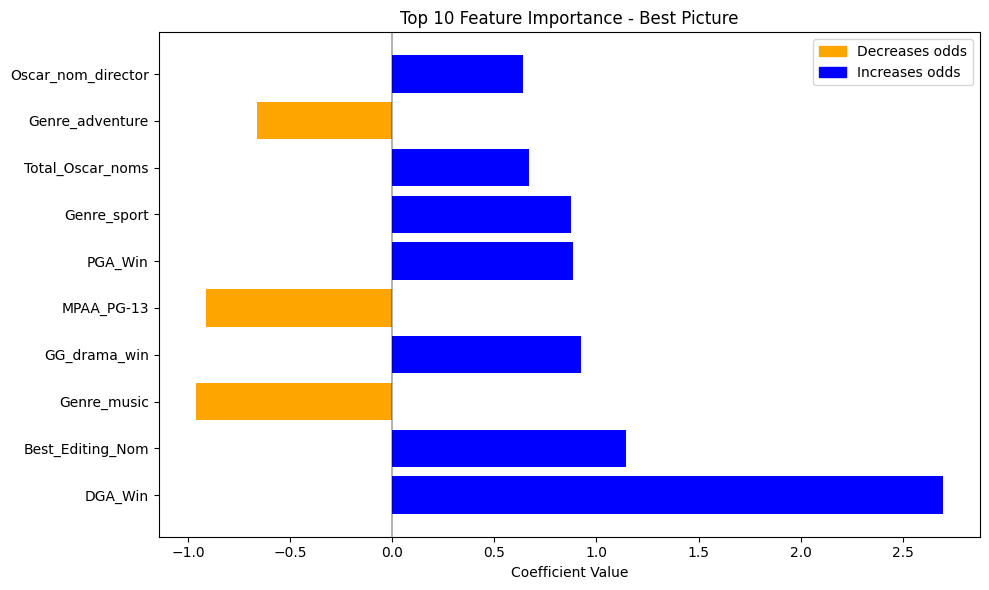

In [20]:
# Best Picture model – Feature importance from coefficients
# Reference: Claude.ai

# Extract features and coefficients from the model
pic_feature_names = pic_train_features.columns
pic_coeffs = pic_logreg_no_pam.coef_[0]

# Create dataframe
pic_importance_df = pd.DataFrame({
    'Feature': pic_feature_names,
    'Coefficient': pic_coeffs,
    'Abs_Coefficient': abs(pic_coeffs)
}).sort_values('Abs_Coefficient', ascending=False)

# Display top 10 most important features
print("Top 10 Most Important Features for Best Picture:")
print(pic_importance_df.head(10))

# Visualising top features
top_pic_features = pic_importance_df.head(10)
colours = ['orange' if coef < 0 else 'blue' for coef in top_pic_features['Coefficient']]

plt.figure(figsize=(10, 6))
plt.barh(top_pic_features['Feature'], top_pic_features['Coefficient'], color=colours)
plt.xlabel('Coefficient Value')
plt.title('Top 10 Feature Importance - Best Picture')
plt.axvline(x=0, color='black', linestyle='-', alpha=0.3)

orange_patch = mpatches.Patch(color='orange', label='Decreases odds')
blue_patch = mpatches.Patch(color='blue', label='Increases odds')
plt.legend(handles=[orange_patch, blue_patch], loc='best')

plt.tight_layout()
plt.show()

# **BEST DIRECTOR MODEL**

### SPLITTING AND SCALING

In [22]:
# Import the data file

dir_data = '1BezSRiMMpzHxcaMXZWDJ6g-H6BjnMi6p'
dir_url = f'https://drive.google.com/uc?id={dir_data}'

dir_df = pd.read_csv(dir_url)
dir_df

,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_dir_noms_count,Prev_Oscar_dir_wins_count,Oscar_nom_picture,Total_Oscar_noms,Rating_IMDB,Rating_rtaudience,...,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken,Prev_Oscar_dir_nom_bin,Prev_Oscar_dir_win_bin,Age_at_Ceremony,Born_in_America,Gender
0,The Apartment,1961,Billy Wilder,1,0,0,1,10,8.3,94,...,0,0,125,1,1,0,0,55,0,Male
1,Sons and Lovers,1961,Jack Cardiff,0,0,0,1,7,7.3,54,...,0,0,103,0,1,0,0,47,0,Male
2,Never on Sunday,1961,Jules Dassin,0,0,0,0,4,7.4,83,...,0,0,91,0,1,0,0,50,1,Male
3,Psycho,1961,Alfred Hitchcock,0,0,0,0,4,8.5,94,...,1,0,109,1,1,0,0,62,0,Male
4,The Sundowners,1961,Fred Zinnemann,0,0,0,1,5,7.2,62,...,0,0,133,1,1,0,0,54,0,Male
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320,Anora,2025,Sean Baker,1,0,0,1,6,7.8,90,...,1,0,139,1,1,0,0,54,1,Male
321,The Brutalist,2025,Brady Corbet,0,0,0,1,10,8.0,81,...,1,0,215,1,1,0,0,37,1,Male
322,A Complete Unknown,2025,James Mangold,0,0,0,1,8,7.7,96,...,1,0,140,1,1,0,0,62,1,Male
323,Emilia Perez,2025,Jacques Audiard,0,0,0,1,13,5.9,19,...,1,0,132,1,1,0,0,73,0,Male


In [23]:
# Creating new ID column, for identifying rows after training

# new Film and Nominee columns with underscore after title
dir_df['Film_'] = dir_df['Film'] + '_'
dir_df['Nominee_'] = dir_df['Nominee'] + '_'

# new Oscar_Year column as string
dir_df['Oscar_Year_string'] = dir_df['Oscar_Year'].astype(str)

# combining two new columns to create Nominee_ID
dir_df['Nominee_ID'] = dir_df['Nominee_'] + dir_df['Film_'] + dir_df['Oscar_Year_string']

# dropping columns no longer needed
dir_df = dir_df.drop(columns=['Nominee', 'Nominee_', 'Film', 'Film_', 'Oscar_Year_string'])

# moving Nominee_ID so is first column
# Reference: https://www.geeksforgeeks.org/python/how-to-move-a-column-to-first-position-in-pandas-dataframe/
col = dir_df.pop('Nominee_ID')
dir_df.insert(0, 'Nominee_ID', col)

dir_df

,Nominee_ID,Oscar_Year,Winner,Prev_Oscar_dir_noms_count,Prev_Oscar_dir_wins_count,Oscar_nom_picture,Total_Oscar_noms,Rating_IMDB,Rating_rtaudience,Rating_rtcritic,...,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken,Prev_Oscar_dir_nom_bin,Prev_Oscar_dir_win_bin,Age_at_Ceremony,Born_in_America,Gender
0,Billy Wilder_The Apartment_1961,1961,1,0,0,1,10,8.3,94,93,...,0,0,125,1,1,0,0,55,0,Male
1,Jack Cardiff_Sons and Lovers_1961,1961,0,0,0,1,7,7.3,54,75,...,0,0,103,0,1,0,0,47,0,Male
2,Jules Dassin_Never on Sunday_1961,1961,0,0,0,0,4,7.4,83,88,...,0,0,91,0,1,0,0,50,1,Male
3,Alfred Hitchcock_Psycho_1961,1961,0,0,0,0,4,8.5,94,96,...,1,0,109,1,1,0,0,62,0,Male
4,Fred Zinnemann_The Sundowners_1961,1961,0,0,0,1,5,7.2,62,78,...,0,0,133,1,1,0,0,54,0,Male
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320,Sean Baker_Anora_2025,2025,1,0,0,1,6,7.8,90,93,...,1,0,139,1,1,0,0,54,1,Male
321,Brady Corbet_The Brutalist_2025,2025,0,0,0,1,10,8.0,81,93,...,1,0,215,1,1,0,0,37,1,Male
322,James Mangold_A Complete Unknown_2025,2025,0,0,0,1,8,7.7,96,80,...,1,0,140,1,1,0,0,62,1,Male
323,Jacques Audiard_Emilia Perez_2025,2025,0,0,0,1,13,5.9,19,74,...,1,0,132,1,1,0,0,73,0,Male


In [24]:
# dropping English_spoken column – decided not to use
dir_df = dir_df.drop(columns=['English_spoken'])

In [25]:
dir_df['Gender'].value_counts()

,count
Gender,
Male,315
Female,10


In [26]:
# converting Gender column into binary values in new column – Male (1) or not (0)
dir_df['Male'] = dir_df['Gender'].map({'Male': 1, 'Female': 0})

In [27]:
# dropping 'Gender' column
dir_df = dir_df.drop(columns=['Gender'])

In [28]:
# Splitting the data
# 80% train, 20% test
# Excluding 5x new features, 2x universal features (Runtime and Produced_in_America), and 3x Ratings

# Extract features, target and groups from main dataframe
dir_features = dir_df[['Prev_Oscar_dir_noms_count', 'Prev_Oscar_dir_wins_count', 'Oscar_nom_picture', 'Total_Oscar_noms',
                       'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                       'BAFTA_Nom', 'BAFTA_Win', 'GG_dir_nom', 'GG_dir_win','DGA_Nom', 'DGA_Win',
                       'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                       'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                       'Genre_family', 'Genre_sport', 'Genre_western',
                       'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17',
                       ]]

dir_target = dir_df['Winner']
dir_groups = dir_df['Oscar_Year']

# Extract Nominee_IDs to apply back to predictions later
dir_ids = dir_df['Nominee_ID']

# set up the splitter
gss_dir = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

# Get index of rows in each split
dir_train_index, dir_test_index = next(gss_dir.split(dir_features, dir_target, dir_groups))

# Split dataset
dir_train_df = dir_df.iloc[dir_train_index]
dir_test_df = dir_df.iloc[dir_test_index]

In [29]:
# Scaling continuous columns all at once

continuous_cols = ['Total_Oscar_noms']
scaler = MinMaxScaler(feature_range=(0, 1))

dir_train_df.loc[:, continuous_cols] = scaler.fit_transform(dir_train_df[continuous_cols])
dir_test_df.loc[:, continuous_cols] = scaler.transform(dir_test_df[continuous_cols])

/tmp/ipython-input-1676169930.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.73333333 0.26666667 0.73333333 0.6        0.46666667 0.66666667
 0.         0.53333333 0.33333333 0.13333333 0.66666667 0.26666667
 0.4        0.46666667 0.8        0.46666667 0.8        0.26666667
 0.8        0.53333333 0.         0.2        0.26666667 0.86666667
 0.46666667 0.26666667 0.46666667 0.66666667 0.66666667 0.8
 0.46666667 0.26666667 0.2        0.53333333 0.66666667 0.06666667
 0.06666667 0.46666667 0.26666667 0.53333333 0.53333333 0.53333333
 0.26666667 0.26666667 0.66666667 0.33333333 0.13333333 0.66666667
 0.33333333 0.73333333 0.         0.4        0.73333333 0.26666667
 0.         0.26666667 0.2        0.46666667 0.4        0.33333333
 0.73333333 0.73333333 0.6        0.73333333 0.6        0.33333333
 0.53333333 0.8        0.4        0.6        0.53333333 0.6
 0.2        0.33333333 0.4        0.53333333 0.4        

In [30]:
# Extract features, targets and IDs from training and testing data

dir_train_features = dir_train_df[['Prev_Oscar_dir_noms_count', 'Prev_Oscar_dir_wins_count', 'Oscar_nom_picture', 'Total_Oscar_noms',
                       'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                       'BAFTA_Nom', 'BAFTA_Win', 'GG_dir_nom', 'GG_dir_win','DGA_Nom', 'DGA_Win',
                       'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                       'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                       'Genre_family', 'Genre_sport', 'Genre_western',
                       'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17',
                       ]]

dir_train_target = dir_train_df['Winner']
dir_train_ids = dir_train_df['Nominee_ID']

dir_test_features = dir_test_df[['Prev_Oscar_dir_noms_count', 'Prev_Oscar_dir_wins_count', 'Oscar_nom_picture', 'Total_Oscar_noms',
                       'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                       'BAFTA_Nom', 'BAFTA_Win', 'GG_dir_nom', 'GG_dir_win','DGA_Nom', 'DGA_Win',
                       'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                       'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                       'Genre_family', 'Genre_sport', 'Genre_western',
                       'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17',
                       ]]

dir_test_target = dir_test_df['Winner']
dir_test_ids = dir_test_df['Nominee_ID']

### TRAINING BEST DIRECTOR MODEL

In [31]:
# running the Logistic Regression model with default parameters
dir_logreg_no_ratings = LogisticRegression(random_state = 42)

# fitting it to the training data
dir_logreg_no_ratings.fit(dir_train_features, dir_train_target)

LogisticRegression(random_state=42)

In [32]:
# getting prediction probabilites – of winning (1) only
dir_logreg_no_ratings_test_preds = dir_logreg_no_ratings.predict_proba(dir_test_features)[:, 1]
dir_logreg_no_ratings_train_preds = dir_logreg_no_ratings.predict_proba(dir_train_features)[:, 1]

In [33]:
# Evaluation metrics

mse = mean_squared_error(dir_test_target, dir_logreg_no_ratings_test_preds)
mae = mean_absolute_error(dir_test_target, dir_logreg_no_ratings_test_preds)
rmse = np.sqrt(mean_squared_error(dir_test_target, dir_logreg_no_ratings_test_preds))

log_loss_score = log_loss(dir_test_target, dir_logreg_no_ratings_test_preds)

train_auc_roc = roc_auc_score(dir_train_target, dir_logreg_no_ratings_train_preds)
test_auc_roc = roc_auc_score(dir_test_target, dir_logreg_no_ratings_test_preds)
auc_pr = average_precision_score(dir_test_target, dir_logreg_no_ratings_test_preds)

print(f"Best Director Evaluation Metrics – Excluding 3x Ratings:")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Log Loss Score: {log_loss_score:.4f}")
print(f"TRAIN AUC ROC: {train_auc_roc:.4f}")
print(f"TEST AUC ROC: {test_auc_roc:.4f}")
print(f"AUC Precision Recall: {auc_pr:.4f}")

Best Director Evaluation Metrics – Excluding 3x Ratings:
Mean Squared Error (MSE): 0.0351
Mean Absolute Error (MAE): 0.1035
Root Mean Squared Error (RMSE): 0.1874
Log Loss Score: 0.1481
TRAIN AUC ROC: 0.9781
TEST AUC ROC: 0.9749
AUC Precision Recall: 0.9275


In [34]:
# Create results dataframe

dir_test_results_df, dir_train_results_df = create_prediction_results(
    dir_test_ids, dir_train_ids,
    dir_test_target, dir_train_target,
    dir_logreg_no_ratings_test_preds, dir_logreg_no_ratings_train_preds
)

In [35]:
# Top Pick Accuracy and F1 Score

top_1 = calculate_top_n_accuracy(dir_test_results_df, 1)
top_2 = calculate_top_n_accuracy(dir_test_results_df, 2)
top_3 = calculate_top_n_accuracy(dir_test_results_df, 3)
f1 = calculate_f1_score(dir_test_results_df)
train_top_1 = calculate_top_n_accuracy(dir_train_results_df, 1)
train_top_2 = calculate_top_n_accuracy(dir_train_results_df, 2)
train_top_3 = calculate_top_n_accuracy(dir_train_results_df, 3)
train_f1 = calculate_f1_score(dir_train_results_df)

print(f"Best Director Top Pick Accuracy & F1 Score – Excluding 3x Ratings:")
print(f"Top 1 Pick: {top_1:.0%}")
print(f"Top 2 Picks: {top_2:.0%}")
print(f"Top 3 Picks: {top_3:.0%}")
print(f"F1 Score: {f1:.4f}")
print(f"TRAIN Top 1 Pick: {train_top_1:.0%}")
print(f"TRAIN Top 2 Picks: {train_top_2:.0%}")
print(f"TRAIN Top 3 Picks: {train_top_3:.0%}")
print(f"TRAIN F1 Score: {train_f1:.4f}")

Best Director Top Pick Accuracy & F1 Score – Excluding 3x Ratings:
Top 1 Pick: 92%
Top 2 Picks: 100%
Top 3 Picks: 100%
F1 Score: 0.9231
TRAIN Top 1 Pick: 91%
TRAIN Top 2 Picks: 94%
TRAIN Top 3 Picks: 96%
TRAIN F1 Score: 0.9231


### BEST DIRECTOR MODEL - CROSS-VALIDATION

In [39]:
# define the model
dir_cv_model = LogisticRegression(random_state = 42, max_iter=1000)

# call function
roc_mean, roc_std, f1_mean, f1_std = cross_validate_oscar_model_dir(
    model = dir_cv_model,
    X = dir_features,
    y = dir_target,
    groups = dir_groups,
    cv_splits=5
)

# print results
print(f"Cross-Validation Results – Best Director Model:")
print(f"ROC-AUC: {roc_mean:.3f} (±{roc_std:.3f})")
print(f"F1 Score: {f1_mean:.3f} (±{f1_std:.3f})")

Cross-Validation Results – Best Director Model:
ROC-AUC: 0.949 (±0.023)
F1 Score: 0.892 (±0.038)


### BEST DIRECTOR MODEL - FEATURE IMPORTANCE

Top 10 Most Important Features for Best Director:
              Feature  Coefficient  Abs_Coefficient
13            DGA_Win     3.656055         3.656055
35         MPAA_PG-13    -1.019918         1.019918
3    Total_Oscar_noms     0.984580         0.984580
12            DGA_Nom     0.977115         0.977115
2   Oscar_nom_picture     0.690842         0.690842
11         GG_dir_win     0.689802         0.689802
33             MPAA_G     0.624045         0.624045
8           BAFTA_Nom     0.592851         0.592851
23        Genre_music     0.566571         0.566571
28     Genre_thriller     0.502247         0.502247


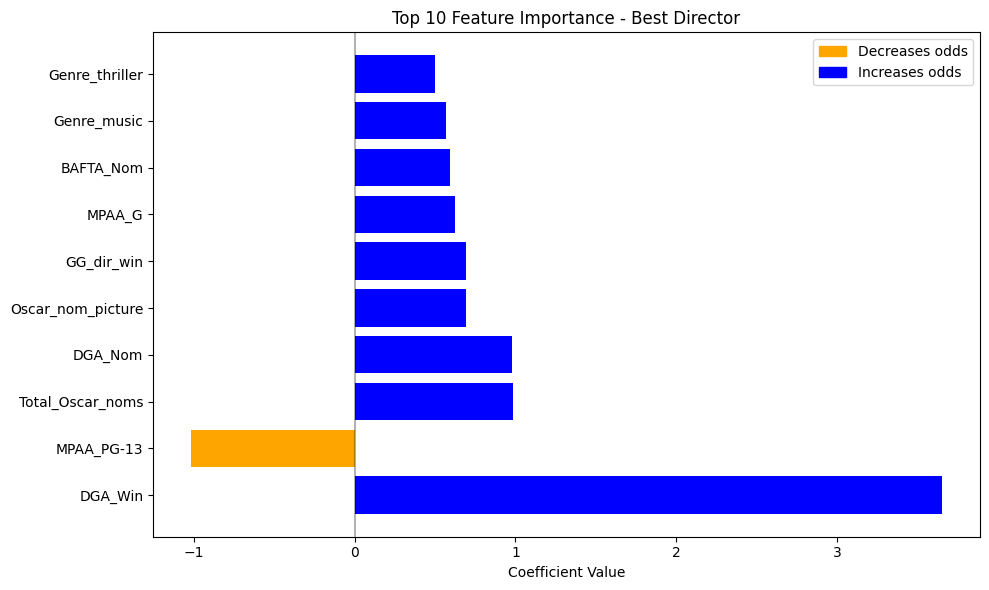

In [36]:
# Best Director model – Feature importance from coefficients
# Reference: Claude.ai

# Extract features and coefficients from the model
dir_feature_names = dir_train_features.columns
dir_coeffs = dir_logreg_no_ratings.coef_[0]

# Create dataframe
dir_importance_df = pd.DataFrame({
    'Feature': dir_feature_names,
    'Coefficient': dir_coeffs,
    'Abs_Coefficient': abs(dir_coeffs)
}).sort_values('Abs_Coefficient', ascending=False)

# Display top 10 most important features
print("Top 10 Most Important Features for Best Director:")
print(dir_importance_df.head(10))

# Visualising top fetures
top_dir_features = dir_importance_df.head(10)
colours = ['orange' if coef < 0 else 'blue' for coef in top_dir_features['Coefficient']]

plt.figure(figsize=(10, 6))
plt.barh(top_dir_features['Feature'], top_dir_features['Coefficient'], color=colours)
plt.xlabel('Coefficient Value')
plt.title('Top 10 Feature Importance - Best Director')
plt.axvline(x=0, color='black', linestyle='-', alpha=0.3)

orange_patch = mpatches.Patch(color='orange', label='Decreases odds')
blue_patch = mpatches.Patch(color='blue', label='Increases odds')
plt.legend(handles=[orange_patch, blue_patch], loc='best')

plt.tight_layout()
plt.show()

# **BEST MALE ACTING MODEL**

### SPLITTING AND SCALING

In [40]:
# Import the data file

act_data = '18V8j_QbeESK-afrY0hoFX6yzZgDeE4y9'
act_url = f'https://drive.google.com/uc?id={act_data}'

act_df = pd.read_csv(act_url)
act_df

,Category,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_act_noms_count,Prev_Oscar_act_wins_count,Prev_Oscar_act_nom_binary,Prev_Oscar_act_win_binary,Oscar_nom_picture,...,Genre_family,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Born_in_America,Real_person
0,Actor,Elmer Gantry,1961,Burt Lancaster,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
1,Actor,Sons and Lovers,1961,Trevor Howard,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,Actor,The Apartment,1961,Jack Lemmon,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
3,Actor,The Entertainer,1961,Laurence Olivier,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,Actor,Inherit the Wind,1961,Spencer Tracy,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1295,Supporting Actress,The Brutalist,2025,Felicity Jones,0,1,0,1,0,1,...,0,0,0,0,0,0,1,0,0,0
1296,Supporting Actress,A Complete Unknown,2025,Monica Barbaro,0,0,0,0,0,1,...,0,0,0,0,0,0,1,0,1,1
1297,Supporting Actress,Conclave,2025,Isabella Rossellini,0,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
1298,Supporting Actress,Emilia Perez,2025,Zoe Saldana,1,0,0,0,0,1,...,0,0,0,0,0,0,1,0,1,0


In [41]:
# Creating new ID column, for identifying rows after training

# new Film, Nominee and Category columns with underscore after title
act_df['Film_'] = act_df['Film'] + '_'
act_df['Nominee_'] = act_df['Nominee'] + '_'
act_df['Category_'] = act_df['Category'] + '_'

# new Oscar_Year column as string
act_df['Oscar_Year_string'] = act_df['Oscar_Year'].astype(str)

# combining two new columns to create Nominee_ID
act_df['Nominee_ID'] = act_df['Nominee_'] + act_df['Film_'] + act_df['Category_'] + act_df['Oscar_Year_string']

# dropping columns no longer needed
# keeping Category column in act_df as think might need it later
act_df = act_df.drop(columns=['Nominee', 'Nominee_', 'Film', 'Film_', 'Oscar_Year_string'])

# moving Nominee_ID so is first column
col = act_df.pop('Nominee_ID')
act_df.insert(0, 'Nominee_ID', col)

act_df

,Nominee_ID,Category,Oscar_Year,Winner,Prev_Oscar_act_noms_count,Prev_Oscar_act_wins_count,Prev_Oscar_act_nom_binary,Prev_Oscar_act_win_binary,Oscar_nom_picture,Total_Oscar_noms,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Born_in_America,Real_person,Category_
0,Burt Lancaster_Elmer Gantry_Actor_1961,Actor,1961,1,0,0,0,0,1,5,...,0,0,0,0,0,0,0,1,0,Actor_
1,Trevor Howard_Sons and Lovers_Actor_1961,Actor,1961,0,0,0,0,0,1,7,...,0,0,0,0,0,0,0,0,0,Actor_
2,Jack Lemmon_The Apartment_Actor_1961,Actor,1961,0,0,0,0,0,1,10,...,0,0,0,0,0,0,0,1,0,Actor_
3,Laurence Olivier_The Entertainer_Actor_1961,Actor,1961,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,Actor_
4,Spencer Tracy_Inherit the Wind_Actor_1961,Actor,1961,0,0,0,0,0,0,4,...,0,0,0,0,0,0,0,1,0,Actor_
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1295,Felicity Jones_The Brutalist_Supporting Actres...,Supporting Actress,2025,0,1,0,1,0,1,10,...,0,0,0,0,0,1,0,0,0,Supporting Actress_
1296,Monica Barbaro_A Complete Unknown_Supporting A...,Supporting Actress,2025,0,0,0,0,0,1,8,...,0,0,0,0,0,1,0,1,1,Supporting Actress_
1297,Isabella Rossellini_Conclave_Supporting Actres...,Supporting Actress,2025,0,0,0,0,0,1,8,...,0,0,0,1,0,0,0,0,0,Supporting Actress_
1298,Zoe Saldana_Emilia Perez_Supporting Actress_2025,Supporting Actress,2025,1,0,0,0,0,1,13,...,0,0,0,0,0,1,0,1,0,Supporting Actress_


In [42]:
# defining categories for each gender
male_categories = ['Actor', 'Supporting Actor']

# creating male acting df
act_male = act_df[act_df['Category'].isin(male_categories)]

In [45]:
# Splitting the male acting dataset
# 80% train, 20% test

# Extract features, target and groups from main dataframe
# Including all features
act_male_features = act_male[['Prev_Oscar_act_noms_count', 'Prev_Oscar_act_wins_count', 'Prev_Oscar_act_nom_binary', 'Prev_Oscar_act_win_binary', 'Oscar_nom_picture', 'Total_Oscar_noms', 'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic',
                       'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                       'BAFTA_Nom', 'BAFTA_Win', 'GG_acting_nom', 'GG_acting_win','SAG_nom', 'SAG_win', 'Age',
                       'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                       'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                       'Genre_family', 'Genre_sport', 'Genre_western',
                       'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17',
                       'Born_in_America', 'Real_person']]

act_male_target = act_male['Winner']
act_male_groups = act_male['Oscar_Year']

# Extract Nominee_IDs and Categories to apply back to predictions later
act_male_ids = act_male['Nominee_ID']
act_male_category = act_male['Category']

# set up the splitter
gss_act_male = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

# Get index of rows in each split
act_male_train_index, act_male_test_index = next(gss_act_male.split(act_male_features, act_male_target, act_male_groups))

# Split datasets
act_male_train_df = act_male.iloc[act_male_train_index]
act_male_test_df = act_male.iloc[act_male_test_index]

In [46]:
# Scaling continuous columns

continuous_cols = ['Total_Oscar_noms', 'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic', 'Age']
scaler = MinMaxScaler(feature_range=(0, 1))

act_male_train_df.loc[:, continuous_cols] = scaler.fit_transform(act_male_train_df[continuous_cols])
act_male_test_df.loc[:, continuous_cols] = scaler.transform(act_male_test_df[continuous_cols])

/tmp/ipython-input-3851744682.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.78571429 0.78571429 0.35714286 0.64285714 0.07142857 0.78571429
 0.64285714 0.64285714 0.78571429 0.14285714 0.57142857 0.28571429
 0.28571429 0.         0.71428571 0.28571429 0.71428571 0.35714286
 0.07142857 0.21428571 0.35714286 0.71428571 0.14285714 1.
 0.5        0.14285714 0.71428571 0.5        0.42857143 0.21428571
 0.85714286 0.85714286 0.85714286 0.5        0.28571429 0.85714286
 0.85714286 0.07142857 0.14285714 0.07142857 0.57142857 0.
 0.92857143 0.28571429 0.57142857 0.57142857 0.92857143 0.57142857
 0.21428571 0.28571429 0.5        0.71428571 0.5        0.28571429
 0.71428571 0.71428571 0.71428571 0.28571429 0.71428571 0.28571429
 0.07142857 0.14285714 0.07142857 0.85714286 0.5        0.85714286
 0.14285714 0.21428571 0.14285714 0.42857143 0.71428571 0.21428571
 0.14285714 0.28571429 0.5        0.21428571 0.5        0.

In [48]:
# Extract features, targets and IDs from training and testing data

act_male_train_features = act_male_train_df[['Prev_Oscar_act_noms_count', 'Prev_Oscar_act_wins_count', 'Prev_Oscar_act_nom_binary', 'Prev_Oscar_act_win_binary', 'Oscar_nom_picture', 'Total_Oscar_noms',
                                   'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic',
                                   'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                                   'BAFTA_Nom', 'BAFTA_Win', 'GG_acting_nom', 'GG_acting_win','SAG_nom', 'SAG_win', 'Age',
                                   'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                                   'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                                   'Genre_family', 'Genre_sport', 'Genre_western',
                                   'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17',
                                   'Born_in_America', 'Real_person']]

act_male_train_target = act_male_train_df['Winner']
act_male_train_ids = act_male_train_df['Nominee_ID']
act_male_train_category = act_male_train_df['Category']

act_male_test_features = act_male_test_df[['Prev_Oscar_act_noms_count', 'Prev_Oscar_act_wins_count', 'Prev_Oscar_act_nom_binary', 'Prev_Oscar_act_win_binary', 'Oscar_nom_picture', 'Total_Oscar_noms',
                                 'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic',
                                 'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                                 'BAFTA_Nom', 'BAFTA_Win', 'GG_acting_nom', 'GG_acting_win','SAG_nom', 'SAG_win', 'Age',
                                 'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                                 'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                                 'Genre_family', 'Genre_sport', 'Genre_western',
                                 'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17',
                                 'Born_in_America', 'Real_person']]

act_male_test_target = act_male_test_df['Winner']
act_male_test_ids = act_male_test_df['Nominee_ID']
act_male_test_category = act_male_test_df['Category']

### TRAINING BEST MALE ACTING MODEL

In [49]:
# running the Logistic Regression model with default parameters
act_male_logreg = LogisticRegression(random_state = 42)

# fitting it to the training data
act_male_logreg.fit(act_male_train_features, act_male_train_target)

LogisticRegression(random_state=42)

In [50]:
# getting prediction probabilites – of winning (1) only
# both test and training datasets

act_male_logreg_test_preds = act_male_logreg.predict_proba(act_male_test_features)[:, 1]
act_male_logreg_train_preds = act_male_logreg.predict_proba(act_male_train_features)[:, 1]

In [52]:
# Evaluation metrics

male_mse = mean_squared_error(act_male_test_target, act_male_logreg_test_preds)
male_mae = mean_absolute_error(act_male_test_target, act_male_logreg_test_preds)
male_rmse = np.sqrt(mean_squared_error(act_male_test_target, act_male_logreg_test_preds))

male_log_loss_score = log_loss(act_male_test_target, act_male_logreg_test_preds)

male_train_auc_roc = roc_auc_score(act_male_train_target, act_male_logreg_train_preds)
male_auc_roc = roc_auc_score(act_male_test_target, act_male_logreg_test_preds)
male_auc_pr = average_precision_score(act_male_test_target, act_male_logreg_test_preds)

print(f"Evaluation Metrics – Best Male Acting Model:")
print(f"Mean Squared Error (MSE): {male_mse:.4f}")
print(f"Mean Absolute Error (MAE): {male_mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {male_rmse:.4f}")
print(f"Log Loss Score: {male_log_loss_score:.4f}")
print(f"TRAIN AUC ROC: {male_train_auc_roc:.4f}")
print(f"TEST AUC ROC: {male_auc_roc:.4f}")
print(f"AUC Precision Recall: {male_auc_pr:.4f}")

Evaluation Metrics – Best Male Acting Model:
Mean Squared Error (MSE): 0.1070
Mean Absolute Error (MAE): 0.2019
Root Mean Squared Error (RMSE): 0.3271
Log Loss Score: 0.3645
TRAIN AUC ROC: 0.9064
TEST AUC ROC: 0.8255
AUC Precision Recall: 0.6273


In [55]:
# Create results dataframe

male_test_results_df, male_train_results_df = create_acting_results(
    act_male_test_ids, act_male_train_ids,
    act_male_test_target, act_male_train_target,
    act_male_test_category, act_male_train_category,
    act_male_logreg_test_preds, act_male_logreg_train_preds
)

In [56]:
# MALE Acting Top Picks and F1 score

top_1 = calculate_top_n_accuracy(male_test_results_df, 1)
top_2 = calculate_top_n_accuracy(male_test_results_df, 2)
top_3 = calculate_top_n_accuracy(male_test_results_df, 3)
train_top_1 = calculate_top_n_accuracy(male_train_results_df, 1)
train_top_2 = calculate_top_n_accuracy(male_train_results_df, 2)
train_top_3 = calculate_top_n_accuracy(male_train_results_df, 3)

# Calculate F1
f1_by_category = calculate_f1_by_category(male_test_results_df)
train_f1_by_category = calculate_f1_by_category(male_train_results_df)

print(f"Top Pick Accuracy & F1 Score – Best MALE Acting Model:")
print(f"Top 1 Pick: {top_1:.0%}")
print(f"Top 2 Picks: {top_2:.0%}")
print(f"Top 3 Picks: {top_3:.0%}")
print(f"TRAIN Top 1 Pick: {train_top_1:.0%}")
print(f"TRAIN Top 2 Picks: {train_top_2:.0%}")
print(f"TRAIN Top 3 Picks: {train_top_3:.0%}")

print("\nF1 Scores by Acting Category:")
for category, score in f1_by_category.items():
    print(f"{category}: {score:.4f}")

print("\nTRAINING: F1 Scores by Acting Category:")
for category, score in train_f1_by_category.items():
    print(f"{category}: {score:.4f}")

# Overall F1 (average across categories)
overall_f1 = np.mean(list(f1_by_category.values()))
print(f"\nOverall Acting F1: {overall_f1:.4f}")
train_overall_f1 = np.mean(list(train_f1_by_category.values()))
print(f"TRAIN Overall Acting F1: {train_overall_f1:.4f}")

Top Pick Accuracy & F1 Score – Best MALE Acting Model:
Top 1 Pick: 69%
Top 2 Picks: 100%
Top 3 Picks: 100%
TRAIN Top 1 Pick: 81%
TRAIN Top 2 Picks: 88%
TRAIN Top 3 Picks: 94%

F1 Scores by Acting Category:
Actor: 0.7200
Supporting Actor: 0.6154

TRAINING: F1 Scores by Acting Category:
Actor: 0.7647
Supporting Actor: 0.6408

Overall Acting F1: 0.6677
TRAIN Overall Acting F1: 0.7027


### BEST MALE ACTING MODEL – CROSS-VALIDATION

In [58]:
# Cross-validating Best Male Acting model

# define the model
male_cv_model = LogisticRegression(random_state = 42, max_iter=2000)

# call function
roc_mean, roc_std, f1_by_category_mean, f1_by_category_std = cross_validate_oscar_model_acting(
    model = male_cv_model,
    X = act_male_features,
    y = act_male_target,
    groups = act_male_groups,
    cv_splits=5
)

# print results
print(f"Cross-Validation Results – Best MALE Acting Model:")
print(f"ROC-AUC: {roc_mean:.3f} (±{roc_std:.3f})")
for category in f1_by_category_mean:
    print(f"F1 {category}: {f1_by_category_mean[category]:.3f} (±{f1_by_category_std[category]:.3f})")

Cross-Validation Results – Best MALE Acting Model:
ROC-AUC: 0.847 (±0.031)
F1 Actor: 0.656 (±0.091)
F1 Supporting Actor: 0.662 (±0.062)


### BEST MALE ACTING MODEL – FEATURE IMPORTANCE

Top 10 Most Important Features for Best MALE Acting:
                      Feature  Coefficient  Abs_Coefficient
18                    SAG_win     2.716852         2.716852
16              GG_acting_win     1.838620         1.838620
6                 Rating_IMDB     1.080173         1.080173
21            Genre_biography    -1.048566         1.048566
19                        Age     1.033188         1.033188
26              Genre_fantasy    -0.875733         0.875733
14                  BAFTA_Win     0.778207         0.778207
27               Genre_sci-fi     0.699216         0.699216
17                    SAG_nom    -0.648254         0.648254
1   Prev_Oscar_act_wins_count    -0.625022         0.625022


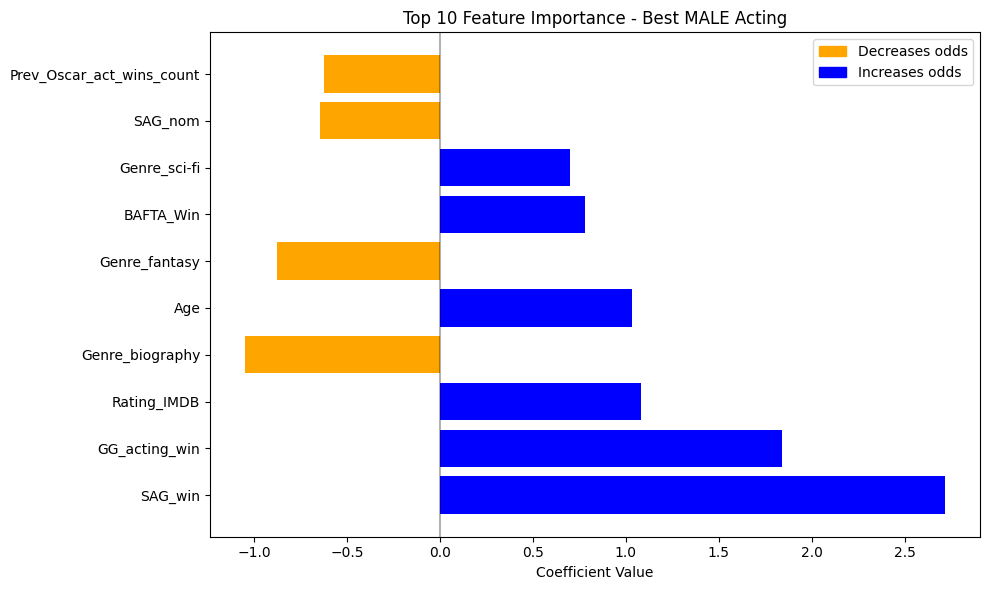

In [57]:
# Best Male Acting model – Feature importance from coefficients
# Reference: Claude.ai

# Extract features and coefficients from the model
act_male_feature_names = act_male_train_features.columns
act_male_coeffs = act_male_logreg.coef_[0]

# Create dataframe
act_male_importance_df = pd.DataFrame({
    'Feature': act_male_feature_names,
    'Coefficient': act_male_coeffs,
    'Abs_Coefficient': abs(act_male_coeffs)
}).sort_values('Abs_Coefficient', ascending=False)

# Display top 10 most important features
print("Top 10 Most Important Features for Best MALE Acting:")
print(act_male_importance_df.head(10))

# Visualising top fetures
top_act_male_features = act_male_importance_df.head(10)
colours = ['orange' if coef < 0 else 'blue' for coef in top_act_male_features['Coefficient']]

plt.figure(figsize=(10, 6))
plt.barh(top_act_male_features['Feature'], top_act_male_features['Coefficient'], color=colours)
plt.xlabel('Coefficient Value')
plt.title('Top 10 Feature Importance - Best MALE Acting')
plt.axvline(x=0, color='black', linestyle='-', alpha=0.3)

orange_patch = mpatches.Patch(color='orange', label='Decreases odds')
blue_patch = mpatches.Patch(color='blue', label='Increases odds')
plt.legend(handles=[orange_patch, blue_patch], loc='best')

plt.tight_layout()
plt.show()

# **BEST FEMALE ACTING MODEL**

### SPLITTING AND SCALING

In [59]:
# Separating female acting data from main act_df

# defining female categories
female_categories = ['Actress', 'Supporting Actress']

# creating female acting df
act_female = act_df[act_df['Category'].isin(female_categories)]

In [60]:
# Splitting each gendered acting dataset
# 80% train, 20% test
# Excluding Real_Person

# Extract features, target and groups from main dataframe
act_female_features = act_female[['Prev_Oscar_act_noms_count', 'Prev_Oscar_act_wins_count', 'Prev_Oscar_act_nom_binary', 'Prev_Oscar_act_win_binary', 'Oscar_nom_picture', 'Total_Oscar_noms', 'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic',
                       'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                       'BAFTA_Nom', 'BAFTA_Win', 'GG_acting_nom', 'GG_acting_win','SAG_nom', 'SAG_win', 'Age',
                       'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                       'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                       'Genre_family', 'Genre_sport', 'Genre_western',
                       'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17',
                       'Born_in_America']]

act_female_target = act_female['Winner']
act_female_groups = act_female['Oscar_Year']

# Extract Nominee_IDs and Categories to apply back to predictions later
act_female_ids = act_female['Nominee_ID']
act_female_category = act_female['Category']


# set up the splitter
gss_act_female = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

# Get index of rows in each split
act_female_train_index, act_female_test_index = next(gss_act_female.split(act_female_features, act_female_target, act_female_groups))

# Split datasets
act_female_train_df = act_female.iloc[act_female_train_index]
act_female_test_df = act_female.iloc[act_female_test_index]

In [61]:
# Scaling continuous columns all at once

continuous_cols = ['Total_Oscar_noms', 'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic', 'Age']
scaler = MinMaxScaler(feature_range=(0, 1))

act_female_train_df.loc[:, continuous_cols] = scaler.fit_transform(act_female_train_df[continuous_cols])
act_female_test_df.loc[:, continuous_cols] = scaler.transform(act_female_test_df[continuous_cols])

/tmp/ipython-input-1979475039.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.6        0.06666667 0.26666667 0.13333333 0.26666667 0.73333333
 0.73333333 0.33333333 0.26666667 0.06666667 0.26666667 0.33333333
 0.33333333 0.06666667 0.2        0.53333333 0.26666667 0.33333333
 0.13333333 0.2        0.13333333 0.46666667 0.         0.33333333
 0.06666667 0.33333333 0.06666667 0.66666667 0.66666667 0.66666667
 0.8        0.06666667 0.4        0.         0.13333333 0.8
 0.46666667 0.26666667 0.         0.06666667 0.86666667 0.26666667
 0.13333333 0.2        0.13333333 0.53333333 0.86666667 0.26666667
 0.4        0.06666667 0.66666667 0.46666667 0.66666667 0.06666667
 0.         0.66666667 0.46666667 0.66666667 0.4        0.06666667
 0.46666667 0.46666667 0.         0.26666667 0.06666667 0.13333333
 0.46666667 0.26666667 0.2        0.13333333 0.13333333 0.46666667
 0.26666667 0.26666667 0.06666667 0.26666667 0.66

In [62]:
# Extract features, targets and IDs from training and testing data
# Excluding Real_Person

act_female_train_features = act_female_train_df[['Prev_Oscar_act_noms_count', 'Prev_Oscar_act_wins_count', 'Prev_Oscar_act_nom_binary', 'Prev_Oscar_act_win_binary', 'Oscar_nom_picture', 'Total_Oscar_noms',
                                   'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic',
                                   'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                                   'BAFTA_Nom', 'BAFTA_Win', 'GG_acting_nom', 'GG_acting_win','SAG_nom', 'SAG_win', 'Age',
                                   'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                                   'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                                   'Genre_family', 'Genre_sport', 'Genre_western',
                                   'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17',
                                   'Born_in_America']]

act_female_train_target = act_female_train_df['Winner']
act_female_train_ids = act_female_train_df['Nominee_ID']
act_female_train_category = act_female_train_df['Category']

act_female_test_features = act_female_test_df[['Prev_Oscar_act_noms_count', 'Prev_Oscar_act_wins_count', 'Prev_Oscar_act_nom_binary', 'Prev_Oscar_act_win_binary', 'Oscar_nom_picture', 'Total_Oscar_noms',
                                 'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic',
                                 'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                                 'BAFTA_Nom', 'BAFTA_Win', 'GG_acting_nom', 'GG_acting_win','SAG_nom', 'SAG_win', 'Age',
                                 'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                                 'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                                 'Genre_family', 'Genre_sport', 'Genre_western',
                                 'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17',
                                 'Born_in_America']]

act_female_test_target = act_female_test_df['Winner']
act_female_test_ids = act_female_test_df['Nominee_ID']
act_female_test_category = act_female_test_df['Category']

### TRAINING BEST FEMALE ACTING MODEL (SVM)

In [63]:
# Support Vector Machines model
act_female_best_svm = SVC(probability=True, random_state=42)

# fitting it to the training data
act_female_best_svm.fit(act_female_train_features, act_female_train_target)

SVC(probability=True, random_state=42)

In [64]:
# getting prediction probabilites – of winning (1) only
# both test and training datasets

# male data
act_female_best_svm_test_preds = act_female_best_svm.predict_proba(act_female_test_features)[:, 1]
act_female_best_svm_train_preds = act_female_best_svm.predict_proba(act_female_train_features)[:, 1]

In [65]:
# Evaluation metrics

female_mse = mean_squared_error(act_female_test_target, act_female_best_svm_test_preds)
female_mae = mean_absolute_error(act_female_test_target, act_female_best_svm_test_preds)
female_rmse = np.sqrt(mean_squared_error(act_female_test_target, act_female_best_svm_test_preds))

female_log_loss_score = log_loss(act_female_test_target, act_female_best_svm_test_preds)

female_train_auc_roc = roc_auc_score(act_female_train_target, act_female_best_svm_train_preds)
female_auc_roc = roc_auc_score(act_female_test_target, act_female_best_svm_test_preds)
female_auc_pr = average_precision_score(act_female_test_target, act_female_best_svm_test_preds)

print(f"Evaluation Metrics – Best FEMALE Acting Model (SVM):")
print(f"Mean Squared Error (MSE): {female_mse:.4f}")
print(f"Mean Absolute Error (MAE): {female_mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {female_rmse:.4f}")
print(f"Log Loss Score: {female_log_loss_score:.4f}")
print(f"TRAIN AUC ROC: {female_train_auc_roc:.4f}")
print(f"TEST AUC ROC: {female_auc_roc:.4f}")
print(f"AUC Precision Recall: {female_auc_pr:.4f}")

Evaluation Metrics – Best FEMALE Acting Model (SVM):
Mean Squared Error (MSE): 0.1216
Mean Absolute Error (MAE): 0.2433
Root Mean Squared Error (RMSE): 0.3486
Log Loss Score: 0.4012
TRAIN AUC ROC: 0.9162
TEST AUC ROC: 0.7581
AUC Precision Recall: 0.5842


In [66]:
# Create results dataframe

female_test_results_df, female_train_results_df = create_acting_results(
    act_female_test_ids, act_female_train_ids,
    act_female_test_target, act_female_train_target,
    act_female_test_category, act_female_train_category,
    act_female_best_svm_test_preds, act_female_best_svm_train_preds
)

In [67]:
# Top Picks and F1 score – Best FEMALE Acting Model

top_1 = calculate_top_n_accuracy(female_test_results_df, 1)
top_2 = calculate_top_n_accuracy(female_test_results_df, 2)
top_3 = calculate_top_n_accuracy(female_test_results_df, 3)
train_top_1 = calculate_top_n_accuracy(female_train_results_df, 1)
train_top_2 = calculate_top_n_accuracy(female_train_results_df, 2)
train_top_3 = calculate_top_n_accuracy(female_train_results_df, 3)

# Calculate F1
f1_by_category = calculate_f1_by_category(female_test_results_df)
train_f1_by_category = calculate_f1_by_category(female_train_results_df)

print(f"FEMALE Acting Top Pick Accuracy & F1 Score – SVM:")
print(f"Top 1 Pick: {top_1:.0%}")
print(f"Top 2 Picks: {top_2:.0%}")
print(f"Top 3 Picks: {top_3:.0%}")
print(f"TRAIN Top 1 Pick: {train_top_1:.0%}")
print(f"TRAIN Top 2 Picks: {train_top_2:.0%}")
print(f"TRAIN Top 3 Picks: {train_top_3:.0%}")

print("\nF1 Scores by Acting Category:")
for category, score in f1_by_category.items():
    print(f"{category}: {score:.4f}")

print("\nTRAINING: F1 Scores by Acting Category:")
for category, score in train_f1_by_category.items():
    print(f"{category}: {score:.4f}")

# Overall F1 (average across categories)
overall_f1 = np.mean(list(f1_by_category.values()))
print(f"\nOverall Acting F1: {overall_f1:.4f}")
train_overall_f1 = np.mean(list(train_f1_by_category.values()))
print(f"TRAIN Overall Acting F1: {train_overall_f1:.4f}")

FEMALE Acting Top Pick Accuracy & F1 Score – SVM:
Top 1 Pick: 69%
Top 2 Picks: 77%
Top 3 Picks: 92%
TRAIN Top 1 Pick: 83%
TRAIN Top 2 Picks: 94%
TRAIN Top 3 Picks: 94%

F1 Scores by Acting Category:
Actress: 0.4615
Supporting Actress: 0.5385

TRAINING: F1 Scores by Acting Category:
Actress: 0.7885
Supporting Actress: 0.7379

Overall Acting F1: 0.5000
TRAIN Overall Acting F1: 0.7632


### BEST FEMALE ACTING MODEL (SVM) – CROSS-VALIDATION

In [68]:
# Cross-validation
# define the model
female_cv_model = SVC(probability=True, random_state=42, max_iter=1000)

# call function
roc_mean, roc_std, f1_by_category_mean, f1_by_category_std = cross_validate_oscar_model_female_acting(
    model = female_cv_model,
    X = act_female_features,
    y = act_female_target,
    groups = act_female_groups,
    cv_splits=5
)

# print results
print(f"Cross-Validation Results – FEMALE ACTING Model 9:")
print(f"ROC-AUC: {roc_mean:.3f} (±{roc_std:.3f})")
for category in f1_by_category_mean:
    print(f"F1 {category}: {f1_by_category_mean[category]:.3f} (±{f1_by_category_std[category]:.3f})")

Cross-Validation Results – FEMALE ACTING Model 9:
ROC-AUC: 0.817 (±0.044)
F1 Actress: 0.692 (±0.161)
F1 Supporting Actress: 0.523 (±0.090)


### BEST LOGISTIC REGRESSION MODEL FOR FEMALE ACTING – TO SEE FEATURE IMPORTANCE

In [69]:
# running the Logistic Regression model with default parameters
# on best Female Acting feature combo – excluding Real Person
act_female_logreg_no_real = LogisticRegression(random_state = 42)

# fitting it to the training data
act_female_logreg_no_real.fit(act_female_train_features, act_female_train_target)

LogisticRegression(random_state=42)

Top 10 Most Important Features for Best FEMALE Acting:
             Feature  Coefficient  Abs_Coefficient
18           SAG_win     2.004008         2.004008
16     GG_acting_win     1.612502         1.612502
14         BAFTA_Win     1.385748         1.385748
5   Total_Oscar_noms     1.333514         1.333514
32         Genre_war     0.926499         0.926499
22       Genre_crime     0.813538         0.813538
17           SAG_nom    -0.771504         0.771504
21   Genre_biography     0.751668         0.751668
8    Rating_rtcritic     0.690315         0.690315
12        Release_Q4    -0.568817         0.568817


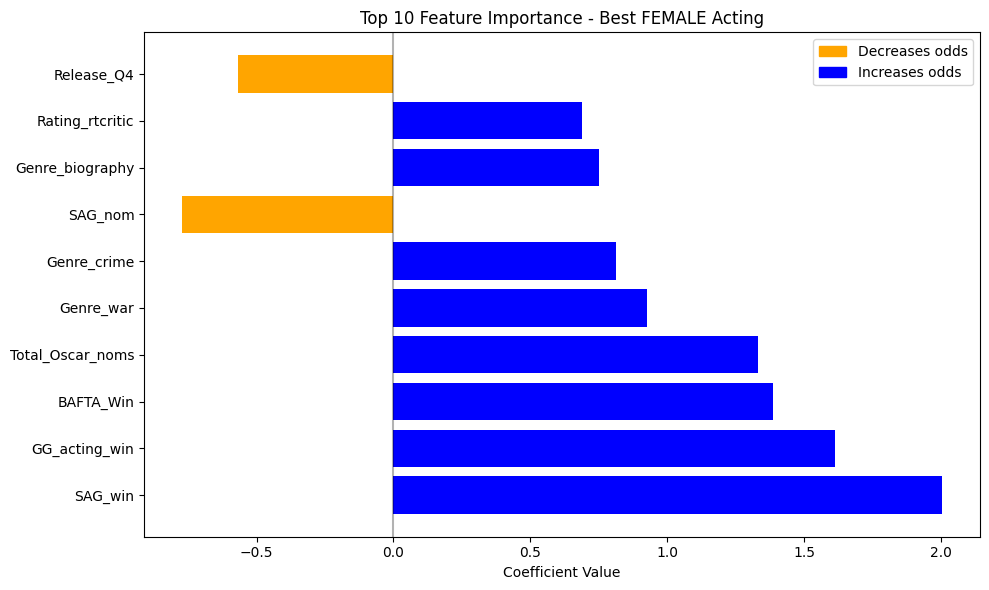

In [70]:
# Best Female Acting (Log Reg) model – Feature importance from coefficients
# Reference: Claude.ai

# Extract features and coefficients from the model
act_female_feature_names = act_female_train_features.columns
act_female_coeffs = act_female_logreg_no_real.coef_[0]

# Create dataframe
act_female_importance_df = pd.DataFrame({
    'Feature': act_female_feature_names,
    'Coefficient': act_female_coeffs,
    'Abs_Coefficient': abs(act_female_coeffs)
}).sort_values('Abs_Coefficient', ascending=False)

# Display top 10 most important features
print("Top 10 Most Important Features for Best FEMALE Acting:")
print(act_female_importance_df.head(10))

# Visualising top fetures
top_act_female_features = act_female_importance_df.head(10)
colours = ['orange' if coef < 0 else 'blue' for coef in top_act_female_features['Coefficient']]

plt.figure(figsize=(10, 6))
plt.barh(top_act_female_features['Feature'], top_act_female_features['Coefficient'], color=colours)
plt.xlabel('Coefficient Value')
plt.title('Top 10 Feature Importance - Best FEMALE Acting')
plt.axvline(x=0, color='black', linestyle='-', alpha=0.3)

orange_patch = mpatches.Patch(color='orange', label='Decreases odds')
blue_patch = mpatches.Patch(color='blue', label='Increases odds')
plt.legend(handles=[orange_patch, blue_patch], loc='best')

plt.tight_layout()
plt.show()

# **References**

Claude.ai. (n.d.) Claude.ai. [Online] Available at: https://claude.ai/ (Accessed: 18 September 2025).

GeeksforGeeks. (2023a) How to generate a train-test split based on a group ID. Available at: https://www.geeksforgeeks.org/machine-learning/how-to-generate-a-train-test-split-based-on-a-group-id/ (Accessed: 18 September 2025).

GeeksforGeeks. (2023b) How to move a column to first position in Pandas DataFrame. Available at: https://www.geeksforgeeks.org/python/how-to-move-a-column-to-first-position-in-pandas-dataframe/ (Accessed: 18 September 2025).

Scikit-learn. (n.d.a) sklearn.ensemble.RandomForestRegressor. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html (Accessed: 18 September 2025).

Scikit-learn. (n.d.b) sklearn.linear_model.LogisticRegression. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html (Accessed: 18 September 2025).

Scikit-learn. (n.d.c) sklearn.model_selection.GroupShuffleSplit. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html (Accessed: 18 September 2025).

Scikit-learn. (n.d.d) sklearn.svm.SVC. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html (Accessed: 18 September 2025).